In [6]:
HEIGHT = 21
WIDTH = 28
FRAMES = 5258
FPS = 1

In [8]:
from query_generator import generate_queries_by_frame
generate_queries_by_frame(HEIGHT, WIDTH, FRAMES, FPS)

Done!                                                  


In [54]:
%%writefile custom.matrix
   A  C  G  T
A  5 -10  5 -10
C -10  5 -10  5
G  5 -10  1 -10
T -10  5 -10  5


Overwriting custom.matrix


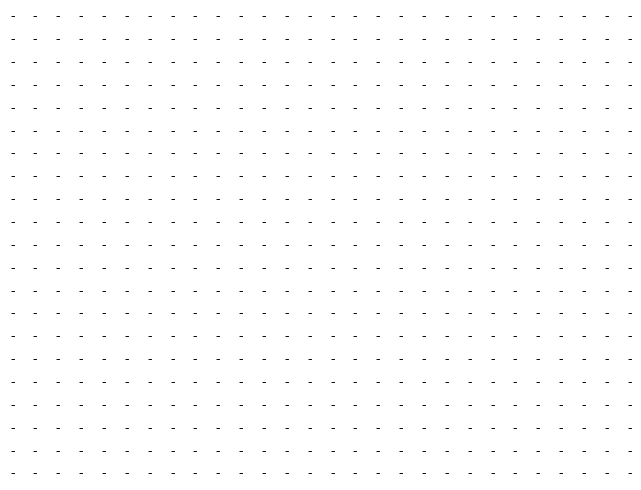

In [55]:
def get_sequence(data):
    if data["status"] != "Sequence found":
        return ""
    s = data["sequence"]
    if data["rev-comp"]:
        return s[::-1].replace("-", "").replace("A", "_").replace("T", "A").replace("_", "T").replace("C", "_").replace("G", "C").replace("_", "G")
    return s

sequences = {}

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

plt.rcParams['font.family'] = 'STIXGeneral'

fig, ax = plt.subplots()
ax.axis("off")

fig_text = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        fig_text[(x, y)] = fig.text(x/WIDTH, 1-y/HEIGHT, "-")
        
def clear():
    for tx in fig_text.values():
        tx.set_text("-")
        tx.set_color((0,0,0))

def draw(i):
#     for x in range(WIDTH):
#         for y in range(HEIGHT):
#             sequence = sequences[(x, y)]
#             if sequence != "":
#                 base = sequence[i]
#                 color = (1,0,0) if base in "CT" else (0,0,1)
#                 fig_text[(x, y)].set_text(base)
#                 fig_text[(x, y)].set_color(color)
    if sequences[i] == "":
        return
    sequence = np.array(list(sequences[i]))[:HEIGHT*WIDTH].reshape((HEIGHT, WIDTH))
    for x in range(WIDTH):
        for y in range(HEIGHT):
            base = sequence[y,x]
            color = (1,0,0) if base in "CT" else (0,0,1)
            fig_text[(x, y)].set_text(base)
            fig_text[(x, y)].set_color(color)

In [60]:
# Sample
!glsearch36 -s custom.matrix -b 1 -d 1 queries/query_0913.fa chr1.fna > sample.output

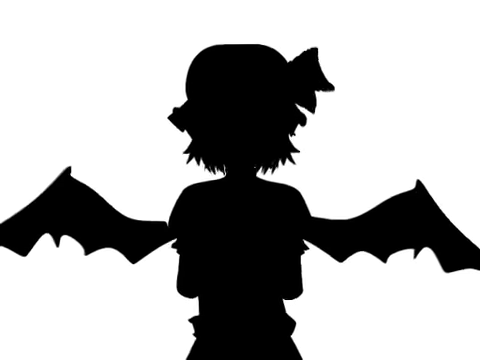

In [61]:
# Sample
from IPython.display import Image
Image(filename='frames/frame913.png')

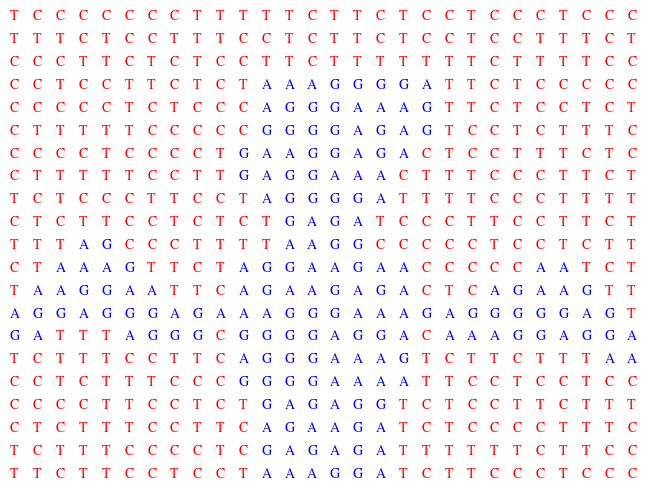

In [62]:
# Sample
with open("queries/query_0913.fa", "r") as f:
    f.readline()
    sequences[-2] = f.readline()
draw(-2)
sequences.pop(-2)
fig

In [ ]:
clear()

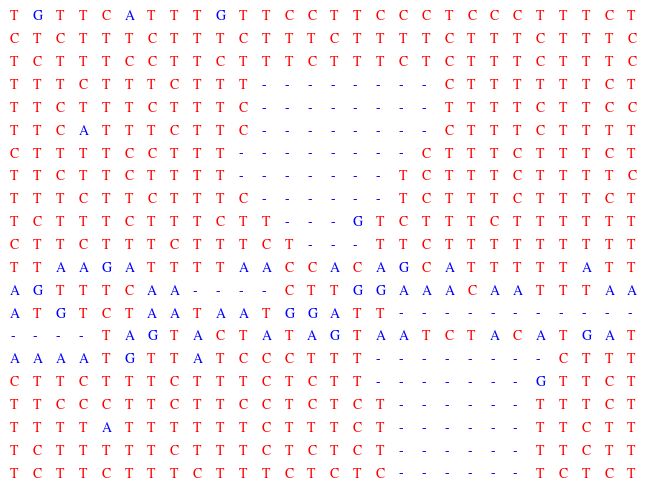

In [63]:
# Sample
from output_parser import parse
sequences[-1] = get_sequence(parse("sample.output"))
draw(-1)
sequences.pop(-1)
fig

In [ ]:
clear()

In [3]:
!. align.sh

Aligning to queries/query_0001.fa
^C


In [4]:
from output_parser import parse_to_json_files
parse_to_json_files()

Parsing outputs/fasta_0001.output
Sequences found: 0
Sequences not found: 1


In [5]:
import json

FRAMES = 170

data = {}
for i in range(1, FRAMES, 24//FPS):
    with open(f"outputs/fasta_{i:04d}.json", "r") as f:
        data[i] = json.loads(f.read())

# data = {}
# for x in range(WIDTH):
#     for y in range(HEIGHT):
#         with open(f"outputs/fasta_{y:02d}_{x:02d}.json", "r") as f:
#             data[(x, y)] = json.loads(f.read())

# data = {}
# for x in range(WIDTH):
#     for y in range(HEIGHT):
#         with open(f"queries/query_{y:02d}_{x:02d}.fa", "r") as f:
#             data[(x, y)] = {
#                 "name": "Test",
#                 "status": "Sequence found",
#                 "sequence": f.read().split('\n')[1]
#             }

print(len(data), "files loaded")

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/fasta_0025.json'

In [ ]:
# sequences = {}
# for x in range(WIDTH):
#     for y in range(HEIGHT):
#         sequences[(x, y)] = get_sequence(data[(x, y)])
        
n = 0
for i in range(1, FRAMES, 24//FPS):
    sequences[n] = get_sequence(data[i])
    n += 1

print(sequences[0])

In [ ]:
ani = animation.FuncAnimation(fig=fig, func=draw, frames=len(sequences), interval=1)

FFwriter = animation.FFMpegWriter(fps=FPS)
ani.save('animation.mp4', writer=FFwriter)

In [ ]:
from IPython.display import Video
Video("animation.mp4")